In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import time
import warnings
warnings.filterwarnings('ignore')
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
import optuna
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [7]:
train_df = pd.read_csv('/content/Fraudulent_E-Commerce_Transaction_Data.csv')

In [8]:
test_df = pd.read_csv('/content/Fraudulent_E-Commerce_Transaction_Data_2.csv')

In [9]:
train_df.head()

,Transaction ID,Customer ID,Transaction Amount,Transaction Date,Payment Method,Product Category,Quantity,Customer Age,Customer Location,Device Used,IP Address,Shipping Address,Billing Address,Is Fraudulent,Account Age Days,Transaction Hour
0,15d2e414-8735-46fc-9e02-80b472b2580f,d1b87f62-51b2-493b-ad6a-77e0fe13e785,58.09,2024-02-20 05:58:41,bank transfer,electronics,1,17,Amandaborough,tablet,212.195.49.198,Unit 8934 Box 0058\nDPO AA 05437,Unit 8934 Box 0058\nDPO AA 05437,0,30,5
1,0bfee1a0-6d5e-40da-a446-d04e73b1b177,37de64d5-e901-4a56-9ea0-af0c24c069cf,389.96,2024-02-25 08:09:45,debit card,electronics,2,40,East Timothy,desktop,208.106.249.121,"634 May Keys\nPort Cherylview, NV 75063","634 May Keys\nPort Cherylview, NV 75063",0,72,8
2,e588eef4-b754-468e-9d90-d0e0abfc1af0,1bac88d6-4b22-409a-a06b-425119c57225,134.19,2024-03-18 03:42:55,PayPal,home & garden,2,22,Davismouth,tablet,76.63.88.212,"16282 Dana Falls Suite 790\nRothhaven, IL 15564","16282 Dana Falls Suite 790\nRothhaven, IL 15564",0,63,3
3,4de46e52-60c3-49d9-be39-636681009789,2357c76e-9253-4ceb-b44e-ef4b71cb7d4d,226.17,2024-03-16 20:41:31,bank transfer,clothing,5,31,Lynnberg,desktop,207.208.171.73,"828 Strong Loaf Apt. 646\nNew Joshua, UT 84798","828 Strong Loaf Apt. 646\nNew Joshua, UT 84798",0,124,20
4,074a76de-fe2d-443e-a00c-f044cdb68e21,45071bc5-9588-43ea-8093-023caec8ea1c,121.53,2024-01-15 05:08:17,bank transfer,clothing,2,51,South Nicole,tablet,190.172.14.169,"29799 Jason Hills Apt. 439\nWest Richardtown, ...","29799 Jason Hills Apt. 439\nWest Richardtown, ...",0,158,5


In [10]:
train_df.shape

(1472952, 16)

In [11]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1472952 entries, 0 to 1472951
Data columns (total 16 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   Transaction ID      1472952 non-null  object 
 1   Customer ID         1472952 non-null  object 
 2   Transaction Amount  1472952 non-null  float64
 3   Transaction Date    1472952 non-null  object 
 4   Payment Method      1472952 non-null  object 
 5   Product Category    1472952 non-null  object 
 6   Quantity            1472952 non-null  int64  
 7   Customer Age        1472952 non-null  int64  
 8   Customer Location   1472952 non-null  object 
 9   Device Used         1472952 non-null  object 
 10  IP Address          1472952 non-null  object 
 11  Shipping Address    1472952 non-null  object 
 12  Billing Address     1472952 non-null  object 
 13  Is Fraudulent       1472952 non-null  int64  
 14  Account Age Days    1472952 non-null  int64  
 15  Transaction Hou

In [12]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Transaction Amount,1472952.0,226.768309,270.395099,10.0,68.61,151.76,296.05,12701.75
Quantity,1472952.0,3.000230,1.414736,1.0,2.00,3.00,4.00,5.00
Customer Age,1472952.0,34.512081,10.003134,-16.0,28.00,35.00,41.00,86.00
Is Fraudulent,1472952.0,0.050129,0.218212,0.0,0.00,0.00,0.00,1.00
Account Age Days,1472952.0,179.646398,106.864223,1.0,86.00,179.00,272.00,365.00
Transaction Hour,1472952.0,11.286964,6.975995,0.0,5.00,11.00,17.00,23.00


- we can see that **Customer age** minimun value is -16 which is not possible so we have to fix the **Customer Age** Column

In [13]:
train_df.describe(include="O")

,Transaction ID,Customer ID,Transaction Date,Payment Method,Product Category,Customer Location,Device Used,IP Address,Shipping Address,Billing Address
count,1472952,1472952,1472952,1472952,1472952,1472952,1472952,1472952,1472952,1472952
unique,1472952,1472952,1346684,4,5,99135,3,1472651,1472948,1472949
top,15d2e414-8735-46fc-9e02-80b472b2580f,d1b87f62-51b2-493b-ad6a-77e0fe13e785,2024-01-27 04:00:16,credit card,health & beauty,New Michael,mobile,170.118.178.249,USS Sanchez\nFPO AE 14652,USCGC Holmes\nFPO AA 56289
freq,1,1,6,368429,295367,1258,491743,2,2,2


### Check missing value

In [14]:
train_df.isnull().sum()

,0
Transaction ID,0
Customer ID,0
Transaction Amount,0
Transaction Date,0
Payment Method,0
Product Category,0
Quantity,0
Customer Age,0
Customer Location,0
Device Used,0


- There is no such missing value

In [15]:
train_df.duplicated().sum()

0

- No duplicate value

In [16]:
train_df.head(2)

,Transaction ID,Customer ID,Transaction Amount,Transaction Date,Payment Method,Product Category,Quantity,Customer Age,Customer Location,Device Used,IP Address,Shipping Address,Billing Address,Is Fraudulent,Account Age Days,Transaction Hour
0,15d2e414-8735-46fc-9e02-80b472b2580f,d1b87f62-51b2-493b-ad6a-77e0fe13e785,58.09,2024-02-20 05:58:41,bank transfer,electronics,1,17,Amandaborough,tablet,212.195.49.198,Unit 8934 Box 0058\nDPO AA 05437,Unit 8934 Box 0058\nDPO AA 05437,0,30,5
1,0bfee1a0-6d5e-40da-a446-d04e73b1b177,37de64d5-e901-4a56-9ea0-af0c24c069cf,389.96,2024-02-25 08:09:45,debit card,electronics,2,40,East Timothy,desktop,208.106.249.121,"634 May Keys\nPort Cherylview, NV 75063","634 May Keys\nPort Cherylview, NV 75063",0,72,8


In [17]:
px.box(data_frame=train_df,x="Customer Age",width=500,height=300)

In [18]:
def clean_data(df) -> pd.DataFrame:

    df["Transaction Date"] = pd.to_datetime(df["Transaction Date"])


    df['Transaction Day'] = df["Transaction Date"].dt.day
    df["Transaction DOW"] = df["Transaction Date"].dt.day_of_week
    df["Transaction Month"] = df["Transaction Date"].dt.month



    '''
    The lower fence of the customer age is 9. We will replace values between -9 and 8 with the mean,
    and values less than -9 will be replaced with their absolute values.
    '''
    mean_value = np.round(df['Customer Age'].mean(),0)
    df['Customer Age'] = np.where(df['Customer Age'] <= -9,
                                    np.abs(df['Customer Age']),
                                    df['Customer Age'])

    df['Customer Age'] = np.where(df['Customer Age'] < 9,
                                    mean_value,
                                    df['Customer Age'])


    df["Is Address Match"] = (df["Shipping Address"] == df["Billing Address"]).astype(int)


    df.drop(columns=["Transaction ID", "Customer ID", "Customer Location",
                     "IP Address", "Transaction Date","Shipping Address","Billing Address"], inplace=True)


    int_col = df.select_dtypes(include="int").columns
    float_col = df.select_dtypes(include="float").columns

    df[int_col] = df[int_col].apply(pd.to_numeric, downcast='integer')
    df[float_col] = df[float_col].apply(pd.to_numeric, downcast='float')

    return df

In [19]:
train_df = clean_data(train_df)

In [20]:
train_df.head()

,Transaction Amount,Payment Method,Product Category,Quantity,Customer Age,Device Used,Is Fraudulent,Account Age Days,Transaction Hour,Transaction Day,Transaction DOW,Transaction Month,Is Address Match
0,58.090000,bank transfer,electronics,1,17.0,tablet,0,30,5,20,1,2,1
1,389.959991,debit card,electronics,2,40.0,desktop,0,72,8,25,6,2,1
2,134.190002,PayPal,home & garden,2,22.0,tablet,0,63,3,18,0,3,1
3,226.169998,bank transfer,clothing,5,31.0,desktop,0,124,20,16,5,3,1
4,121.529999,bank transfer,clothing,2,51.0,tablet,0,158,5,15,0,1,1


In [21]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1472952 entries, 0 to 1472951
Data columns (total 13 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   Transaction Amount  1472952 non-null  float32
 1   Payment Method      1472952 non-null  object 
 2   Product Category    1472952 non-null  object 
 3   Quantity            1472952 non-null  int8   
 4   Customer Age        1472952 non-null  float32
 5   Device Used         1472952 non-null  object 
 6   Is Fraudulent       1472952 non-null  int8   
 7   Account Age Days    1472952 non-null  int16  
 8   Transaction Hour    1472952 non-null  int8   
 9   Transaction Day     1472952 non-null  int8   
 10  Transaction DOW     1472952 non-null  int8   
 11  Transaction Month   1472952 non-null  int8   
 12  Is Address Match    1472952 non-null  int8   
dtypes: float32(2), int16(1), int8(7), object(3)
memory usage: 57.6+ MB


- The dataset has been cleaned and compressed, reducing its size from 180 MB to 52 MB.

# <center style="background-color: #cc7f35; padding: 15px; border-radius: 20px;">📊 EDA (Exploratory Data Analysis) 📊 </center>

<Axes: xlabel='Transaction Amount', ylabel='Count'>

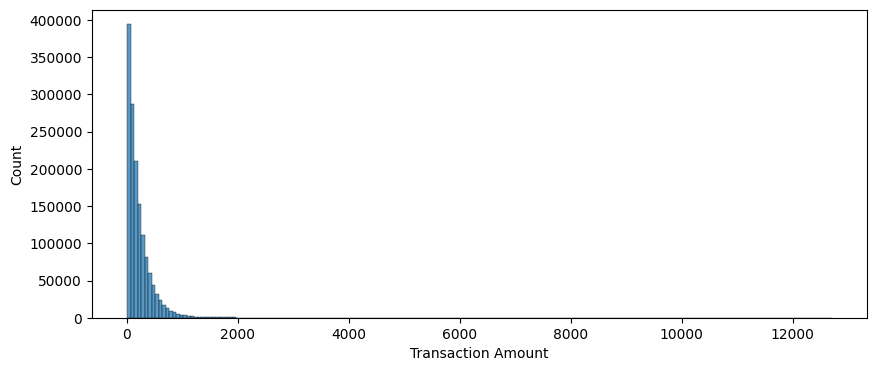

In [22]:
plt.figure(figsize=(10,4))
sns.histplot(train_df["Transaction Amount"],bins=200)

- The maximum transaction amount is between 0 and 1000
- The data is right-skewed.

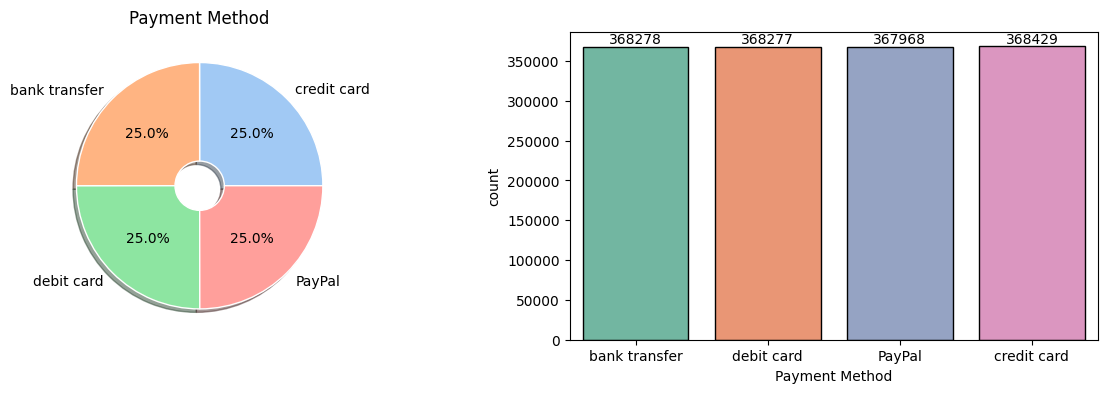

In [23]:
payment_count = train_df["Payment Method"].value_counts()
plt.figure(figsize=(15,4))
plt.subplot(1,2,1)
sns.set_palette('pastel')
colors = sns.color_palette()
plt.pie(payment_count,labels = payment_count.index,shadow=True,autopct='%1.1f%%',
        colors=colors,
        wedgeprops=dict(width=0.8,edgecolor="w"))
plt.title("Payment Method")

plt.subplot(1,2,2)

ax = sns.countplot(data=train_df,x="Payment Method",edgecolor="black",linewidth=1, palette="Set2")
for container in ax.containers:
    ax.bar_label(container)


- We can see that all the Payment Methods are distributed equally

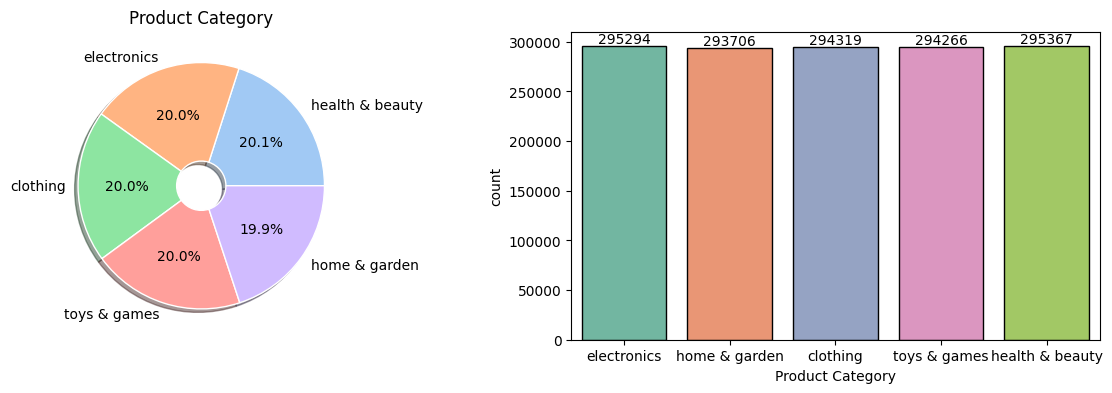

In [24]:
category_count = train_df["Product Category"].value_counts()
plt.figure(figsize=(15,4))
plt.subplot(1,2,1)
sns.set_palette('pastel')
colors = sns.color_palette()
plt.pie(category_count,labels = category_count.index,shadow=True,autopct='%1.1f%%',
        colors=colors,
        wedgeprops=dict(width=0.8,edgecolor="w"))
plt.title("Product Category")

plt.subplot(1,2,2)

ax = sns.countplot(data=train_df,x="Product Category",edgecolor="black",linewidth=1, palette="Set2")
for container in ax.containers:
    ax.bar_label(container)

- We can see that all the Product Categories are also distributed equally

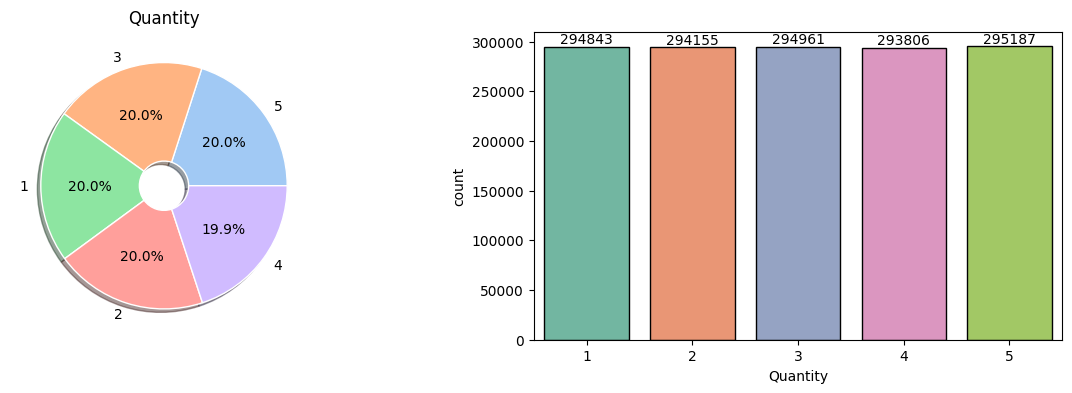

In [25]:
quantity_count = train_df["Quantity"].value_counts()
plt.figure(figsize=(15,4))
plt.subplot(1,2,1)
sns.set_palette('pastel')
colors = sns.color_palette()
plt.pie(quantity_count,labels = quantity_count.index,shadow=True,autopct='%1.1f%%',
        colors=colors,
        wedgeprops=dict(width=0.8,edgecolor="w"))
plt.title("Quantity")

plt.subplot(1,2,2)

ax = sns.countplot(data=train_df,x="Quantity",edgecolor="black",linewidth=1, palette="Set2")
for container in ax.containers:
    ax.bar_label(container)

- We can see that all the Quantity are also distributed equally

<Axes: xlabel='Customer Age', ylabel='Count'>

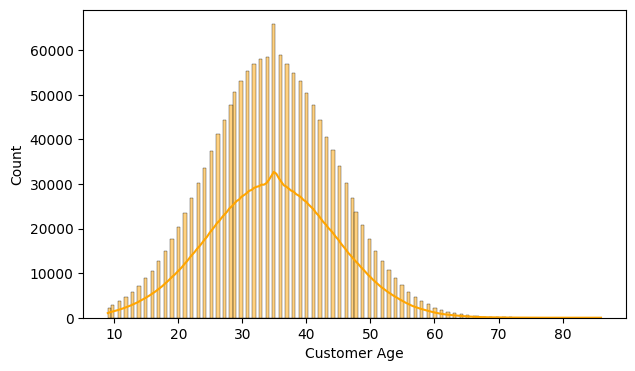

In [26]:
plt.figure(figsize=(7,4))
sns.histplot(data=train_df, x="Customer Age",bins=150,kde=True,color='orange')

- Data is normally distributed

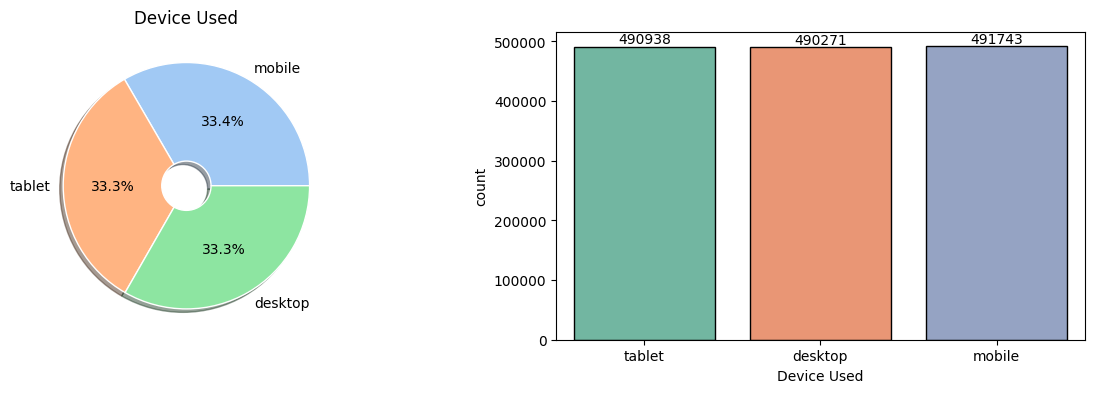

In [27]:
device_count = train_df["Device Used"].value_counts()
plt.figure(figsize=(15,4))
plt.subplot(1,2,1)
sns.set_palette('pastel')
colors = sns.color_palette()
plt.pie(device_count,labels = device_count.index,shadow=True,autopct='%1.1f%%',
        colors=colors,
        wedgeprops=dict(width=0.8,edgecolor="w"))
plt.title("Device Used")

plt.subplot(1,2,2)

ax = sns.countplot(data=train_df,x="Device Used",edgecolor="black",linewidth=1, palette="Set2")
for container in ax.containers:
    ax.bar_label(container)

<Axes: xlabel='Account Age Days', ylabel='Count'>

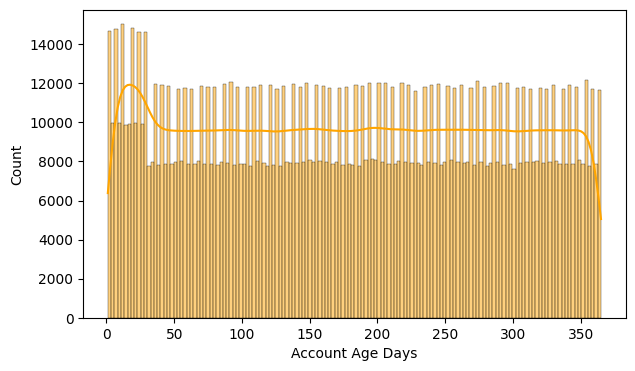

In [28]:
plt.figure(figsize=(7,4))
sns.histplot(data=train_df, x="Account Age Days",bins=150,kde=True,color='orange')

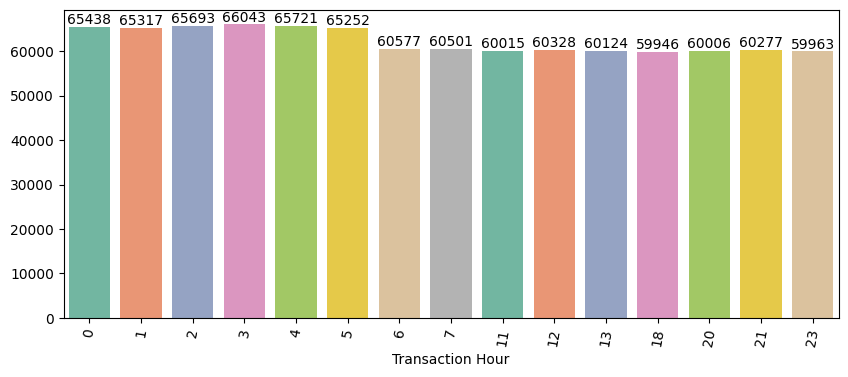

In [29]:

hour_count = train_df["Transaction Hour"].value_counts().head(15)

plt.figure(figsize=(10,4))
sns.set_palette('Set2')
colors = sns.color_palette()
ax=sns.barplot(x=hour_count.index, y=hour_count.values,palette=colors)
plt.xticks(rotation=80)
for container in ax.containers:
    ax.bar_label(container)
plt.show()

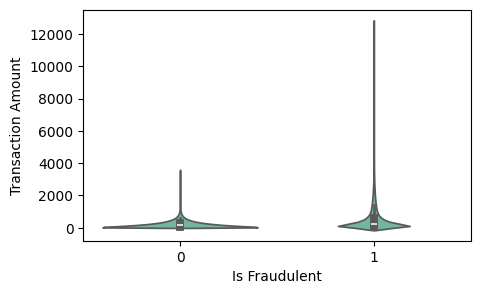

In [30]:
plt.figure(figsize=(5,3))
sns.violinplot(data=train_df, x='Is Fraudulent', y='Transaction Amount')
plt.show()

In [31]:
column = ['Payment Method', 'Product Category',
       'Quantity', 'Device Used','Transaction DOW',
       'Transaction Month','Is Address Match']

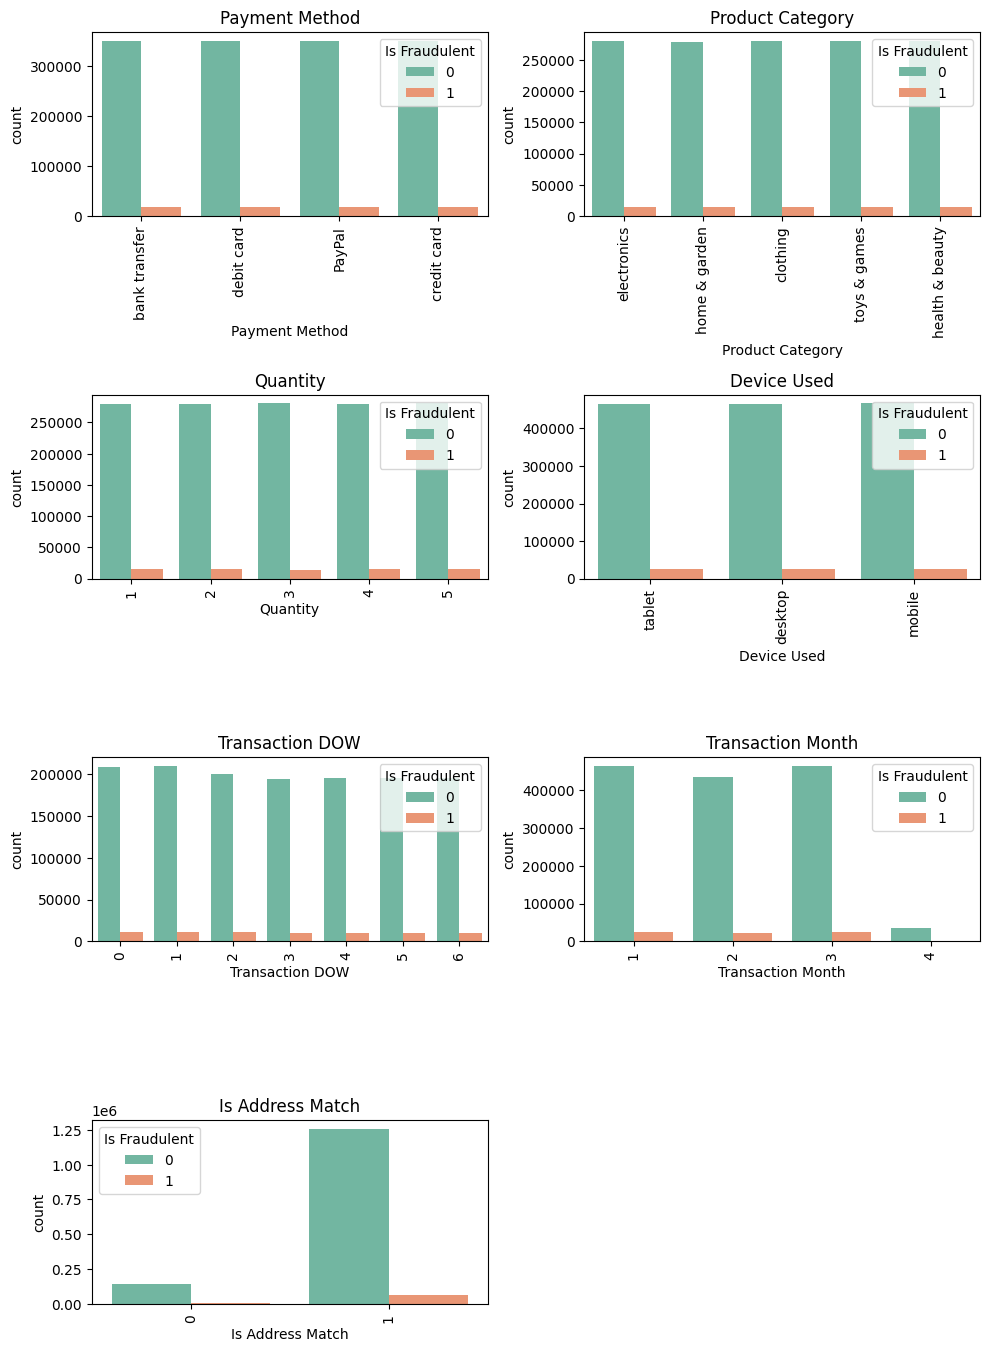

In [32]:
plt.figure(figsize=(10,35))
plot_num = 1
for col in column:
    plt.subplot(10,2,plot_num)
    sns.countplot(data=train_df, x=col, hue="Is Fraudulent")
    plt.xticks(rotation=90)
    plt.title(col)
    plt.tight_layout()
    plot_num += 1

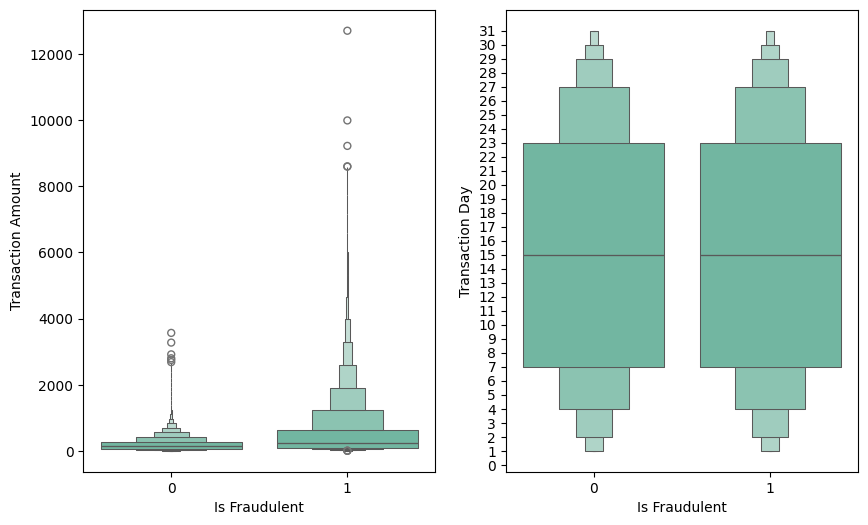

In [33]:
plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
sns.boxenplot(x='Is Fraudulent', y='Transaction Amount', data=train_df)
plt.subplot(1,2,2)
sns.boxenplot(x='Is Fraudulent', y='Transaction Day', data=train_df)
plt.yticks(np.arange(0,32))
plt.show()

**FEATURE ENGINEERING**

In [34]:
import pandas as pd

data1 = pd.read_csv('/content/Fraudulent_E-Commerce_Transaction_Data.csv')
data2 = pd.read_csv('/content/Fraudulent_E-Commerce_Transaction_Data_2.csv')

combined_data = pd.concat([data1, data2], ignore_index=True)

target_column = 'target'

numerical_features = combined_data.select_dtypes(include=['number']).columns

correlation_matrix = combined_data[numerical_features].corr()

if target_column in combined_data.columns:
    target_corr = correlation_matrix[target_column].sort_values(ascending=False) if target_column in correlation_matrix else None
else:
    target_corr = None

threshold = 0.1

selected_features = correlation_matrix.columns[
    (correlation_matrix.abs().max() > threshold)
].tolist()

print("Selected Features:", selected_features)

if target_corr is not None:
    print("Feature Correlations with Target:")
    print(target_corr)

Selected Features: ['Transaction Amount', 'Quantity', 'Customer Age', 'Is Fraudulent', 'Account Age Days', 'Transaction Hour']


In [35]:
all_features = list(correlation_matrix.columns)
non_selected_features = list(set(all_features) - set(selected_features))

print("Selected Features:", selected_features)
print("Non-Selected Features:", non_selected_features)

Selected Features: ['Transaction Amount', 'Quantity', 'Customer Age', 'Is Fraudulent', 'Account Age Days', 'Transaction Hour']
Non-Selected Features: []


# <center style="background-color: #cc7f35; padding: 15px; border-radius: 20px;">🛠️Model Building & Training🛠️ </center>

In [36]:

train_data = train_df.drop(columns=["Is Fraudulent"])
train_label = train_df["Is Fraudulent"]


clean_test_df = clean_data(test_df)
test_data = clean_test_df.drop(columns=["Is Fraudulent"])
test_label = clean_test_df["Is Fraudulent"]

In [37]:
cat_col = train_data.select_dtypes(include="O").columns
num_col = []
for col in train_data.columns:
    if col not in cat_col  and col != 'Is Address Match':
        num_col.append(col)

In [38]:
transformer = ColumnTransformer(transformers=[
    ('encoding',OneHotEncoder(),cat_col),
    ('scaling',StandardScaler(),num_col)
],remainder='passthrough')

In [39]:
classifiers = {
    "Logistic Regression" : LogisticRegression(),
    "Bernoulli NB" : BernoulliNB(),
    "Decision Tree" : DecisionTreeClassifier(),
    "Random Forest" : RandomForestClassifier(),
    "XGB": XGBClassifier()
}

In [40]:
%%time

classifier_name = []
accuracy = []
for name, classifier in classifiers.items():

    model = Pipeline(steps=[
        ('transformer',transformer),
        ('classifier',classifier)
    ])

    start_time = time.time()

    model.fit(train_data, train_label)

    training_time = time.time() - start_time

    test_pred = model.predict(test_data)


    ## Evaluate Model

    acc_score = accuracy_score(test_label, test_pred)
    conf_mat = confusion_matrix(test_label, test_pred)
    class_report = classification_report(test_label, test_pred)
    print(f"Classifier name : {name}")
    print(f"Accuracy score : {acc_score}")
    print(f"Confusion maxtrix : \n{conf_mat}")
    print(f"Classification report :\n{class_report}")
    print(f"{name} Training time: {training_time:.2f} seconds")
    print("="*55)

    classifier_name.append(name)
    accuracy.append(acc_score)

Classifier name : Logistic Regression
Accuracy score : 0.9531607006854531
Confusion maxtrix : 
[[22386    26]
 [ 1081   141]]
Classification report :
              precision    recall  f1-score   support

           0       0.95      1.00      0.98     22412
           1       0.84      0.12      0.20      1222

    accuracy                           0.95     23634
   macro avg       0.90      0.56      0.59     23634
weighted avg       0.95      0.95      0.94     23634

Logistic Regression Training time: 5.06 seconds
Classifier name : Bernoulli NB
Accuracy score : 0.9482948294829483
Confusion maxtrix : 
[[22412     0]
 [ 1222     0]]
Classification report :
              precision    recall  f1-score   support

           0       0.95      1.00      0.97     22412
           1       0.00      0.00      0.00      1222

    accuracy                           0.95     23634
   macro avg       0.47      0.50      0.49     23634
weighted avg       0.90      0.95      0.92     23634

Berno

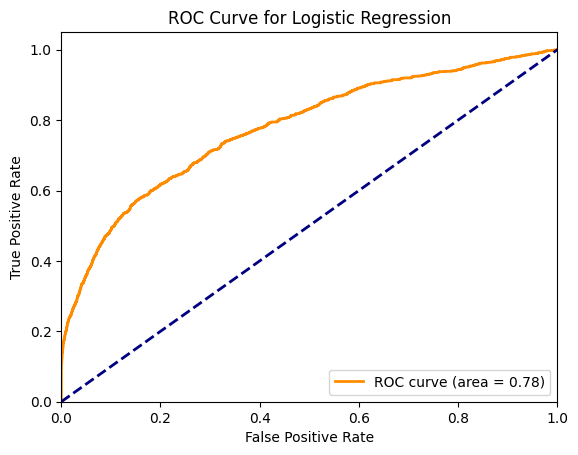

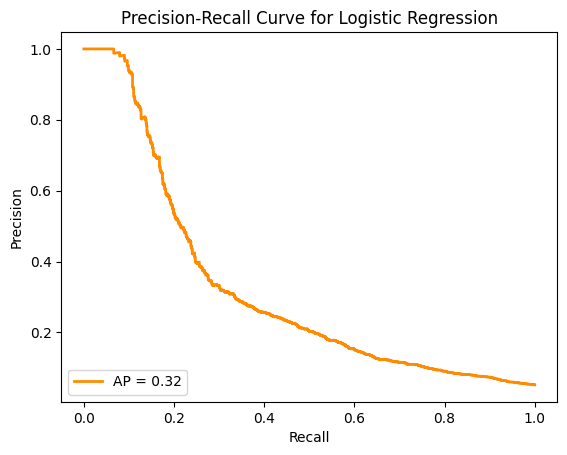

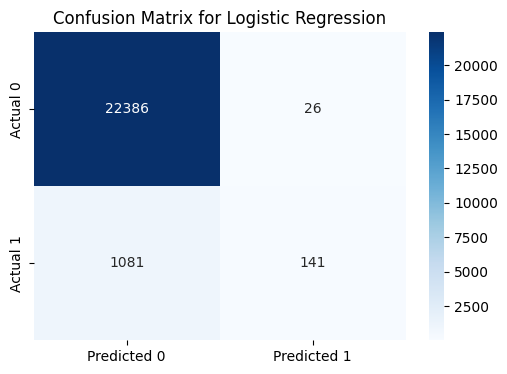

Feature Importance not available for Logistic Regression


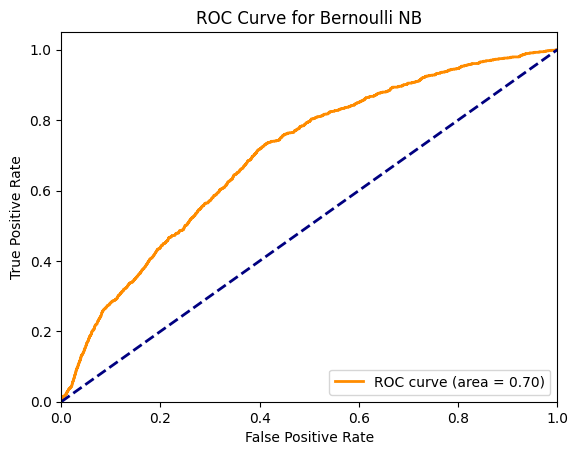

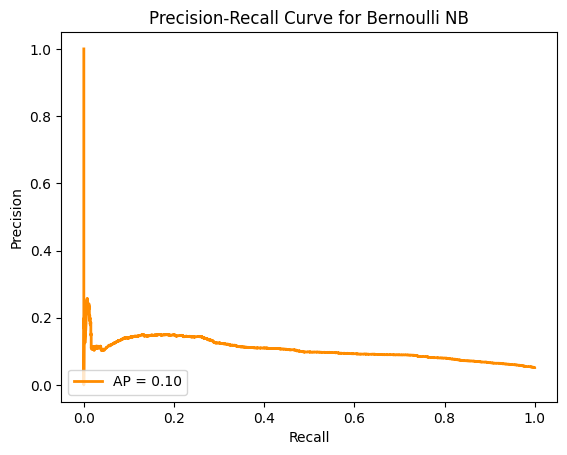

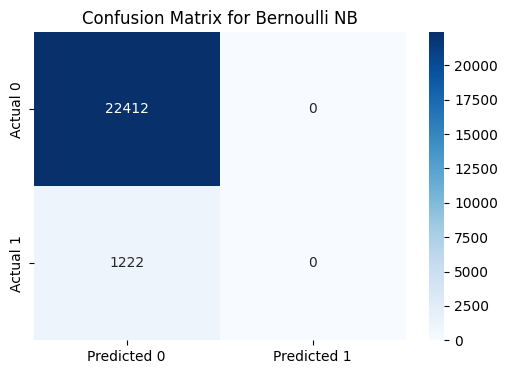

Feature Importance not available for Bernoulli NB


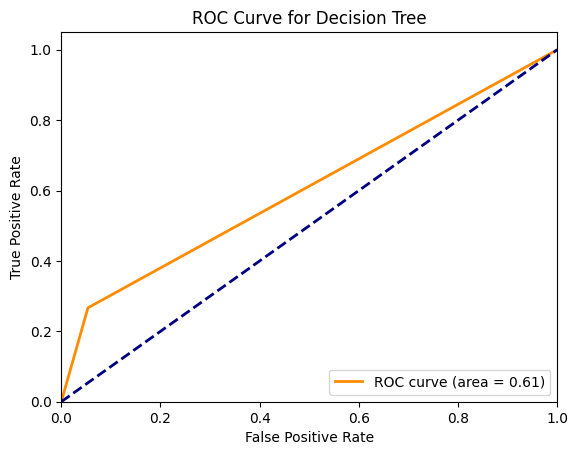

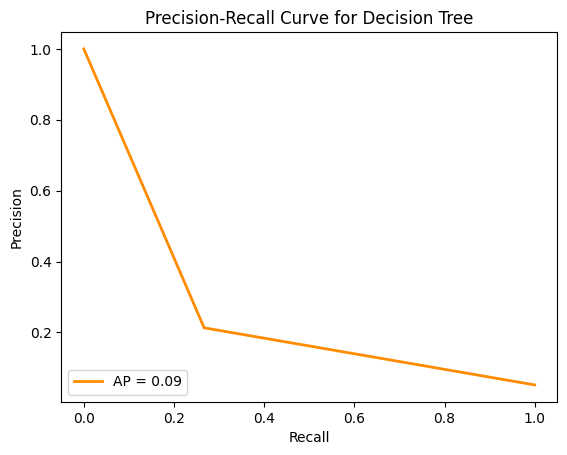

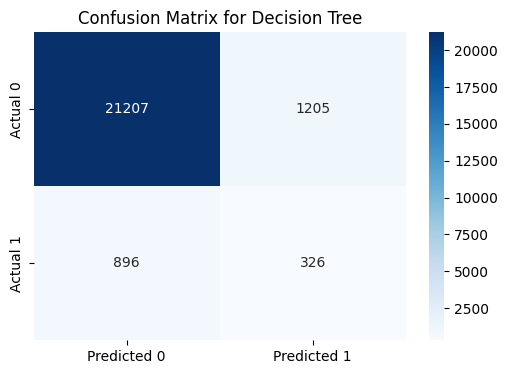

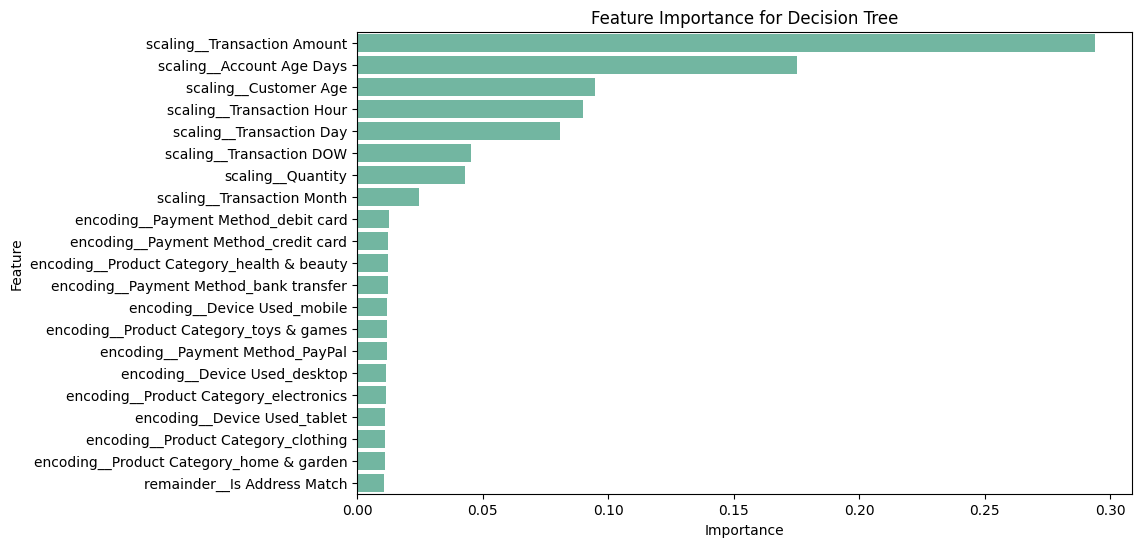

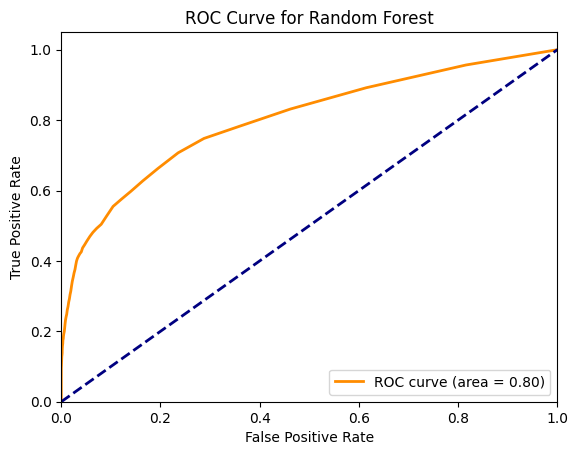

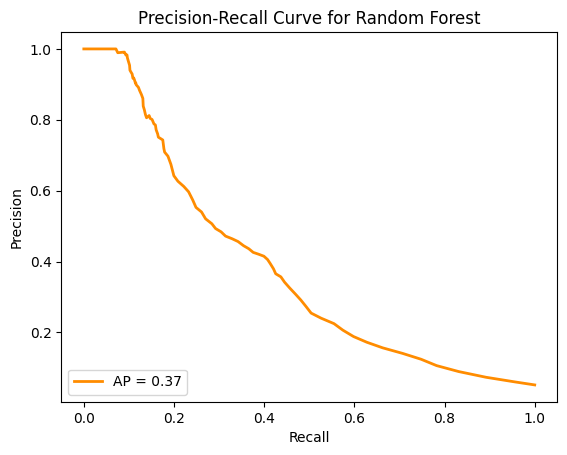

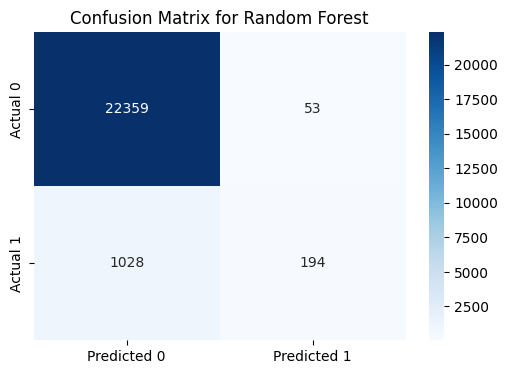

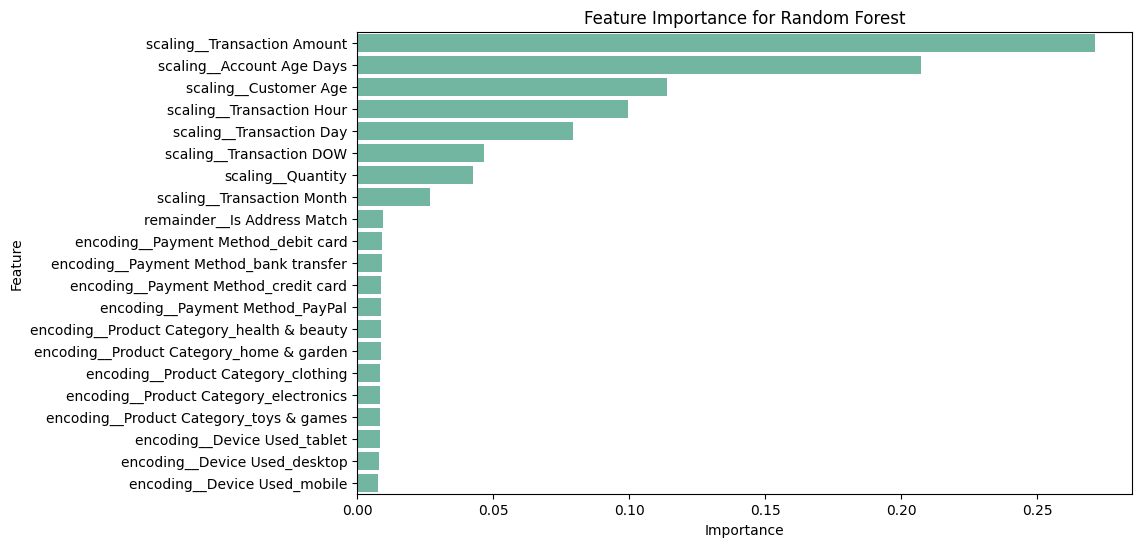

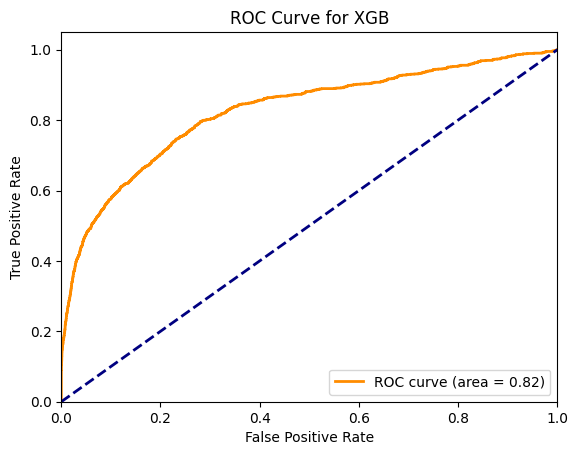

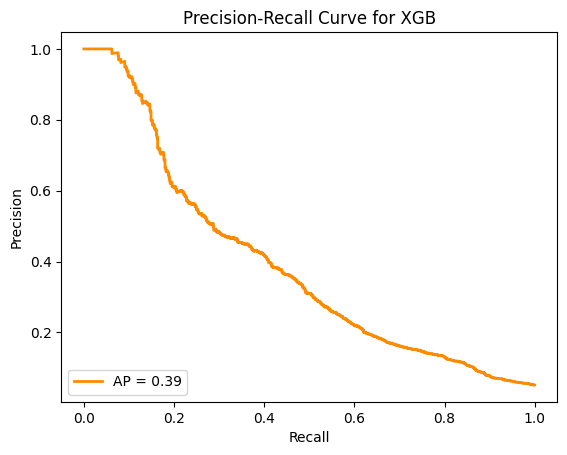

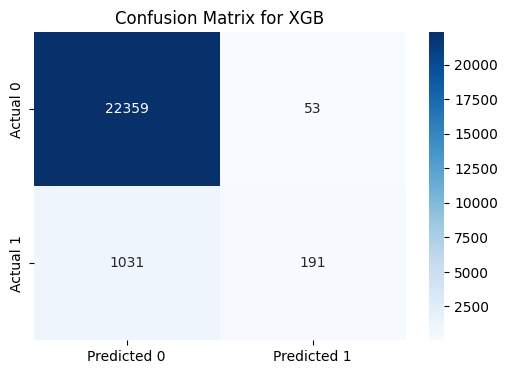

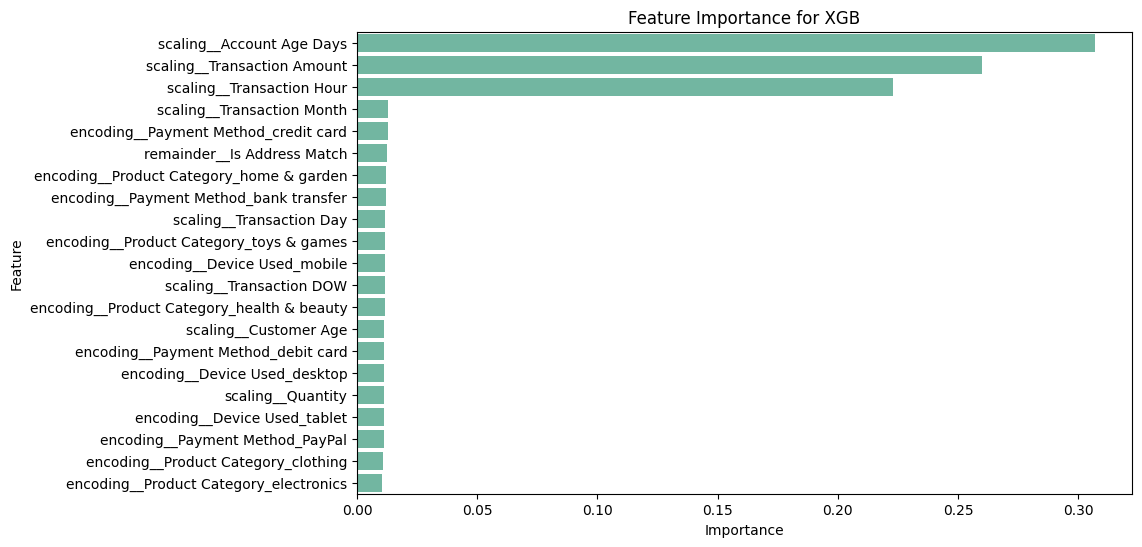

In [44]:
# prompt: what plots can i show for the for each models

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import pandas as pd # explicitly importing pandas

# Assuming 'classifiers', 'train_data', 'train_label', 'test_data', and 'test_label' are defined as in the original code.

for name, classifier in classifiers.items():
    model = Pipeline(steps=[
        ('transformer', transformer),
        ('classifier', classifier)
    ])
    model.fit(train_data, train_label)
    test_pred_proba = model.predict_proba(test_data)[:, 1]  # Probability of positive class

    # 1. ROC Curve
    fpr, tpr, thresholds = roc_curve(test_label, test_pred_proba)
    roc_auc = auc(fpr, tpr)

    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for {name}')
    plt.legend(loc="lower right")
    plt.show()

    # 2. Precision-Recall Curve
    precision, recall, thresholds = precision_recall_curve(test_label, test_pred_proba)
    average_precision = average_precision_score(test_label, test_pred_proba)

    plt.figure()
    plt.plot(recall, precision, color='darkorange', lw=2, label=f'AP = {average_precision:.2f}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve for {name}')
    plt.legend(loc="lower left")
    plt.show()

    # 3. Confusion Matrix (Heatmap)
    test_pred = model.predict(test_data)
    conf_mat = confusion_matrix(test_label, test_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues",
                xticklabels=['Predicted 0', 'Predicted 1'],
                yticklabels=['Actual 0', 'Actual 1'])
    plt.title(f'Confusion Matrix for {name}')
    plt.show()

    # 4. Feature Importance (if applicable)
    try:
        feature_importances = model.named_steps['classifier'].feature_importances_

        # Get feature names after transformation
        feature_names = model.named_steps['transformer'].get_feature_names_out(input_features=train_data.columns)

        importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
        importance_df = importance_df.sort_values(by='Importance', ascending=False)
        plt.figure(figsize=(10, 6))
        sns.barplot(x='Importance', y='Feature', data=importance_df)
        plt.title(f'Feature Importance for {name}')
        plt.show()
    except AttributeError:
        print(f"Feature Importance not available for {name}")

### Model Comparision

In [ ]:
pd.DataFrame({"Classifier name" : classifier_name, "Accuracy" : accuracy}).sort_values(by="Accuracy",ascending=False)

- Based on the results, **XGBoost** appears to perform the best. We will proceed with hyperparameter tuning for **XGBoost** to further improve its performance.

# <center style="background-color: #cc7f35; padding: 15px; border-radius: 20px;">⚙️Hyperparameter Tuning🔧</center>

## Optuna

In [ ]:
!pip install xgboost --upgrade --force-reinstall

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.9/153.9 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.4/16.4 MB 56.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.0/199.0 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 MB 19.5 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nccl-cu12
    Found existing installation: nvidia-nccl-cu12 2.23.4
    Uninstalling nvidia-nccl-cu12-2.23.4:
      Successfully uninstalled nvidia-nccl-cu12-2.23.4
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
  Attempting uninstall: scipy
    Found existing installation: scipy 1.13.1
    Uninstalling scipy-1.13.1:
      Successfully uninstalled scipy-1.13.1
  Attempting uninstall: x

In [ ]:
import optuna
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier


def objective(trial):

    params = {
              "learning_rate": trial.suggest_float("learning_rate", 0.001, 3.0),
              "n_estimators": trial.suggest_int("n_estimators", 100, 700),
              "max_depth": trial.suggest_int("max_depth", 3, 20),
              "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
              "gamma": trial.suggest_float("gamma", 0.0, 1.0),
              "subsample": trial.suggest_float("subsample", 0.01, 1.0),
              "colsample_bytree": trial.suggest_float("colsample_bytree", 0.01, 1.0),
              "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 1.0),
              }

    # Remove "tree_method": "gpu_hist" or change it to "hist" for CPU
    # params["tree_method"] = "hist" # For CPU

    classifier = XGBClassifier(**params)

    model = Pipeline(steps=[
        ('transformer',transformer),
        ('classifier',classifier)
    ])
    model.fit(train_data, train_label)

    # Evaluate model performance
    preds = model.predict(test_data)
    accuracy = accuracy_score(test_label, preds)

    return accuracy


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=70)


best_params = study.best_params
best_trial = study.best_trial

print("Best Hyperparameters:", best_params)
print("Best Accuracy:", best_trial.value)

[I 2024-12-10 04:19:48,268] A new study created in memory with name: no-name-570a5c15-bb5f-40c2-80e9-f51894e1c8c5
[I 2024-12-10 04:21:06,214] Trial 0 finished with value: 0.9537530676144538 and parameters: {'learning_rate': 0.4373316223359317, 'n_estimators': 429, 'max_depth': 9, 'min_child_weight': 10, 'gamma': 0.5713513585107916, 'subsample': 0.2914170908368896, 'colsample_bytree': 0.11052453580864117, 'reg_alpha': 0.5241442901729149}. Best is trial 0 with value: 0.9537530676144538.
[I 2024-12-10 04:22:58,116] Trial 1 finished with value: 0.9482948294829483 and parameters: {'learning_rate': 2.674649554337371, 'n_estimators': 533, 'max_depth': 7, 'min_child_weight': 10, 'gamma': 0.6077454501505726, 'subsample': 0.426401180531762, 'colsample_bytree': 0.5954285701153795, 'reg_alpha': 0.07810130349875688}. Best is trial 0 with value: 0.9537530676144538.
[I 2024-12-10 04:23:44,721] Trial 2 finished with value: 0.9491833798764492 and parameters: {'learning_rate': 0.6515751188035307, 'n_est

Best Hyperparameters: {'learning_rate': 0.27953005034293954, 'n_estimators': 359, 'max_depth': 20, 'min_child_weight': 1, 'gamma': 0.7684858831815174, 'subsample': 0.3133085196071611, 'colsample_bytree': 0.049638300165696425, 'reg_alpha': 0.8692298579004081}
Best Accuracy: 0.9544300583904545


In [ ]:
optuna.visualization.plot_optimization_history(study)

`plot_optimization_history`
   - Visualizes the objective function scores of all trials during optimization.
   - Tracks the best score found so far throughout the optimization process.

In [ ]:
optuna.visualization.plot_parallel_coordinate(study)

`plot_parallel_coordinate`
   - Visualizes relationships between hyperparameters and scores.
   - Interactive exploration of parameter effects.

In [ ]:
optuna.visualization.plot_slice(study)

- Slice plots are ideal for exploring the effect of a single hyperparameter on the target metric in a machine learning experiment.

In [ ]:
optuna.visualization.plot_param_importances(study)

- `Learning rate` and `minimum child weight` are among the most important parameters for tuning model.

In [ ]:
optuna.visualization.plot_timeline(study)

#### Reference for the `Optuna` hyperparameter tuning

https://www.kaggle.com/code/hamzaghanmi/xgboost-catboost-using-optuna

### If you found this solution helpful, please upvote it! 🔼